<a href="https://colab.research.google.com/github/koustav241013006127tiu/AI-Python/blob/main/labproblem6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Dataset — Original vs SMOTE
**Six classifiers:** Logistic Regression, Decision Tree, Random Forest, SVM, KNN, ANN.

**Method:** Split the original dataset first. Apply SMOTE only to the training split. Keep the test split untouched and original/imbalanced, so both experiments are evaluated on identical unseen cases without leakage.

In [6]:
# CELL 1 — Install imbalanced-learn
%pip -q install imbalanced-learn
print("imbalanced-learn installed successfully.")

imbalanced-learn installed successfully.


In [7]:
# CELL 2 — Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE
print("All libraries imported successfully.")

All libraries imported successfully.


In [8]:
# CELL 3 — Upload and load CSV
csv_files = [f for f in os.listdir("/content") if f.lower().endswith(".csv")]
if not csv_files:
    print("Upload stroke_processed_5k.csv")
    uploaded = files.upload()
    csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file found. Upload the processed stroke dataset.")
csv_file = "stroke_processed_5k.csv" if "stroke_processed_5k.csv" in csv_files else csv_files[0]
df = pd.read_csv(os.path.join("/content", csv_file))
if "stroke" not in df.columns:
    raise ValueError("Target column 'stroke' was not found.")
print("Loaded:", csv_file, "| Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df.head())

Loaded: stroke_processed_5k (1).csv | Shape: (5110, 11)
Missing values: 0


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


Counts (0=No Stroke, 1=Stroke):


,Count
stroke,
0,4861
1,249


Percentages:


,Percent
stroke,
0,95.13
1,4.87


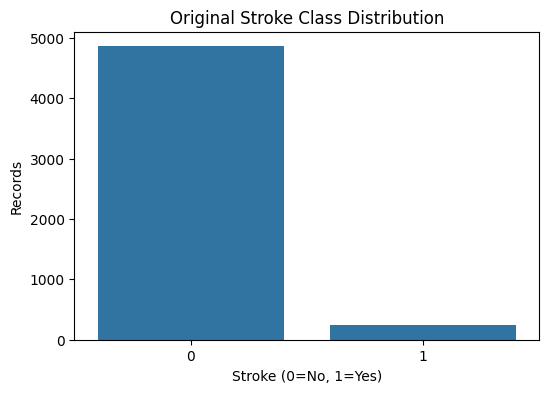

In [9]:
# CELL 4 — Original class distribution + chart
counts = df["stroke"].value_counts().sort_index()
print("Counts (0=No Stroke, 1=Stroke):")
display(counts.to_frame("Count"))
print("Percentages:")
display((df["stroke"].value_counts(normalize=True).sort_index()*100).round(2).to_frame("Percent"))
plt.figure(figsize=(6,4))
sns.barplot(x=counts.index.astype(str), y=counts.values)
plt.title("Original Stroke Class Distribution")
plt.xlabel("Stroke (0=No, 1=Yes)")
plt.ylabel("Records")
plt.show()

In [10]:
# CELL 5 — Features and target
X = df.drop(columns="stroke")
y = df["stroke"]
print("X:", X.shape, "| y:", y.shape)

X: (5110, 10) | y: (5110,)


In [38]:
# CELL 6 — Stratified 80:20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain classes:"); display(y_train.value_counts().sort_index().to_frame("Count"))
print("\nTest classes (unchanged):"); display(y_test.value_counts().sort_index().to_frame("Count"))

Train: (4088, 10) | Test: (1022, 10)

Train classes:


,Count
stroke,
0,3889
1,199



Test classes (unchanged):


,Count
stroke,
0,972
1,50


Training before SMOTE:


,Count
stroke,
0,3889
1,199


Training after SMOTE:


,Count
stroke,
0,3889
1,3889


Test data remains unchanged:


,Count
stroke,
0,972
1,50


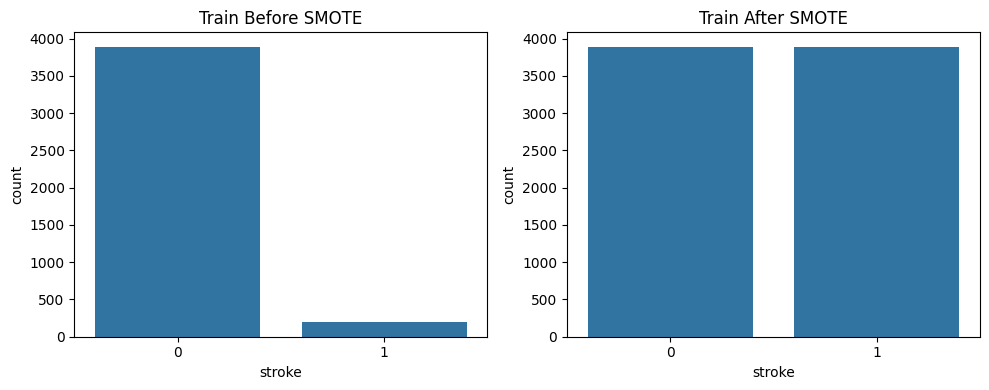

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [12]:
# CELL 7 — SMOTE on TRAINING data only
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("Training before SMOTE:"); display(y_train.value_counts().sort_index().to_frame("Count"))
print("Training after SMOTE:"); display(y_train_smote.value_counts().sort_index().to_frame("Count"))
print("Test data remains unchanged:"); display(y_test.value_counts().sort_index().to_frame("Count"))

fig, ax = plt.subplots(1,2,figsize=(10,4))
sns.countplot(x=y_train, ax=ax[0]); ax[0].set_title("Train Before SMOTE")
sns.countplot(x=y_train_smote, ax=ax[1]); ax[1].set_title("Train After SMOTE")
plt.tight_layout(); plt.show()

In [13]:
# CELL 8 — Define six classifiers
def create_models():
    return {
        "Logistic Regression": Pipeline([("scaler",StandardScaler()),
            ("model",LogisticRegression(max_iter=2000,random_state=42))]),
        "Decision Tree": DecisionTreeClassifier(max_depth=6,min_samples_leaf=5,random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=300,max_depth=10,
            min_samples_leaf=2,random_state=42,n_jobs=-1),
        "SVM": Pipeline([("scaler",StandardScaler()),
            ("model",SVC(C=1,kernel="rbf",probability=True,random_state=42))]),
        "KNN": Pipeline([("scaler",StandardScaler()),
            ("model",KNeighborsClassifier(n_neighbors=7,weights="distance"))]),
        "ANN": Pipeline([("scaler",StandardScaler()),
            ("model",MLPClassifier(hidden_layer_sizes=(32,16),activation="relu",
                solver="adam",alpha=0.001,max_iter=1500,early_stopping=True,
                validation_fraction=0.15,n_iter_no_change=30,random_state=42))])
    }
print("Six classifiers defined.")

Six classifiers defined.


In [14]:
# CELL 9 — Logistic Regression: ORIGINAL training data
model_original_logistic_regression = create_models()["Logistic Regression"]
model_original_logistic_regression.fit(X_train,y_train)
pred_original_logistic_regression = model_original_logistic_regression.predict(X_test)
prob_original_logistic_regression = model_original_logistic_regression.predict_proba(X_test)[:,1]
metrics_original_logistic_regression = {
 "Model":"Logistic Regression",
 "Accuracy":accuracy_score(y_test,pred_original_logistic_regression),
 "Precision":precision_score(y_test,pred_original_logistic_regression,zero_division=0),
 "Recall":recall_score(y_test,pred_original_logistic_regression,zero_division=0),
 "F1-Score":f1_score(y_test,pred_original_logistic_regression,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_original_logistic_regression)
}
print("Logistic Regression — ORIGINAL")
for metric,value in metrics_original_logistic_regression.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

Logistic Regression — ORIGINAL
Accuracy: 0.9511
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC: 0.8377


In [15]:
# CELL 10 — Decision Tree: ORIGINAL training data
model_original_decision_tree = create_models()["Decision Tree"]
model_original_decision_tree.fit(X_train,y_train)
pred_original_decision_tree = model_original_decision_tree.predict(X_test)
prob_original_decision_tree = model_original_decision_tree.predict_proba(X_test)[:,1]
metrics_original_decision_tree = {
 "Model":"Decision Tree",
 "Accuracy":accuracy_score(y_test,pred_original_decision_tree),
 "Precision":precision_score(y_test,pred_original_decision_tree,zero_division=0),
 "Recall":recall_score(y_test,pred_original_decision_tree,zero_division=0),
 "F1-Score":f1_score(y_test,pred_original_decision_tree,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_original_decision_tree)
}
print("Decision Tree — ORIGINAL")
for metric,value in metrics_original_decision_tree.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

Decision Tree — ORIGINAL
Accuracy: 0.9462
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC: 0.7917


In [16]:
# CELL 11 — Random Forest: ORIGINAL training data
model_original_random_forest = create_models()["Random Forest"]
model_original_random_forest.fit(X_train,y_train)
pred_original_random_forest = model_original_random_forest.predict(X_test)
prob_original_random_forest = model_original_random_forest.predict_proba(X_test)[:,1]
metrics_original_random_forest = {
 "Model":"Random Forest",
 "Accuracy":accuracy_score(y_test,pred_original_random_forest),
 "Precision":precision_score(y_test,pred_original_random_forest,zero_division=0),
 "Recall":recall_score(y_test,pred_original_random_forest,zero_division=0),
 "F1-Score":f1_score(y_test,pred_original_random_forest,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_original_random_forest)
}
print("Random Forest — ORIGINAL")
for metric,value in metrics_original_random_forest.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

Random Forest — ORIGINAL
Accuracy: 0.9511
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC: 0.8320


In [17]:
# CELL 12 — SVM: ORIGINAL training data
model_original_svm = create_models()["SVM"]
model_original_svm.fit(X_train,y_train)
pred_original_svm = model_original_svm.predict(X_test)
prob_original_svm = model_original_svm.predict_proba(X_test)[:,1]
metrics_original_svm = {
 "Model":"SVM",
 "Accuracy":accuracy_score(y_test,pred_original_svm),
 "Precision":precision_score(y_test,pred_original_svm,zero_division=0),
 "Recall":recall_score(y_test,pred_original_svm,zero_division=0),
 "F1-Score":f1_score(y_test,pred_original_svm,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_original_svm)
}
print("SVM — ORIGINAL")
for metric,value in metrics_original_svm.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

SVM — ORIGINAL
Accuracy: 0.9511
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC: 0.6108


In [18]:
# CELL 13 — KNN: ORIGINAL training data
model_original_knn = create_models()["KNN"]
model_original_knn.fit(X_train,y_train)
pred_original_knn = model_original_knn.predict(X_test)
prob_original_knn = model_original_knn.predict_proba(X_test)[:,1]
metrics_original_knn = {
 "Model":"KNN",
 "Accuracy":accuracy_score(y_test,pred_original_knn),
 "Precision":precision_score(y_test,pred_original_knn,zero_division=0),
 "Recall":recall_score(y_test,pred_original_knn,zero_division=0),
 "F1-Score":f1_score(y_test,pred_original_knn,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_original_knn)
}
print("KNN — ORIGINAL")
for metric,value in metrics_original_knn.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

KNN — ORIGINAL
Accuracy: 0.9462
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC: 0.6206


In [39]:
# CELL 14 — ANN: ORIGINAL training data
model_original_ann = create_models()["ANN"]
model_original_ann.fit(X_train,y_train)
pred_original_ann = model_original_ann.predict(X_test)
prob_original_ann = model_original_ann.predict_proba(X_test)[:,1]
metrics_original_ann = {
 "Model":"ANN",
 "Accuracy":accuracy_score(y_test,pred_original_ann),
 "Precision":precision_score(y_test,pred_original_ann,zero_division=0),
 "Recall":recall_score(y_test,pred_original_ann,zero_division=0),
 "F1-Score":f1_score(y_test,pred_original_ann,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_original_ann)
}
print("ANN — ORIGINAL")
for metric,value in metrics_original_ann.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

ANN — ORIGINAL
Accuracy: 0.9511
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC: 0.3518


In [20]:
# CELL 15 — Logistic Regression: SMOTE training data
model_smote_logistic_regression = create_models()["Logistic Regression"]
model_smote_logistic_regression.fit(X_train_smote,y_train_smote)
pred_smote_logistic_regression = model_smote_logistic_regression.predict(X_test)
prob_smote_logistic_regression = model_smote_logistic_regression.predict_proba(X_test)[:,1]
metrics_smote_logistic_regression = {
 "Model":"Logistic Regression",
 "Accuracy":accuracy_score(y_test,pred_smote_logistic_regression),
 "Precision":precision_score(y_test,pred_smote_logistic_regression,zero_division=0),
 "Recall":recall_score(y_test,pred_smote_logistic_regression,zero_division=0),
 "F1-Score":f1_score(y_test,pred_smote_logistic_regression,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_smote_logistic_regression)
}
print("Logistic Regression — SMOTE")
for metric,value in metrics_smote_logistic_regression.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

Logistic Regression — SMOTE
Accuracy: 0.7593
Precision: 0.1423
Recall: 0.7800
F1-Score: 0.2407
AUC: 0.8219


In [21]:
# CELL 16 — Decision Tree: SMOTE training data
model_smote_decision_tree = create_models()["Decision Tree"]
model_smote_decision_tree.fit(X_train_smote,y_train_smote)
pred_smote_decision_tree = model_smote_decision_tree.predict(X_test)
prob_smote_decision_tree = model_smote_decision_tree.predict_proba(X_test)[:,1]
metrics_smote_decision_tree = {
 "Model":"Decision Tree",
 "Accuracy":accuracy_score(y_test,pred_smote_decision_tree),
 "Precision":precision_score(y_test,pred_smote_decision_tree,zero_division=0),
 "Recall":recall_score(y_test,pred_smote_decision_tree,zero_division=0),
 "F1-Score":f1_score(y_test,pred_smote_decision_tree,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_smote_decision_tree)
}
print("Decision Tree — SMOTE")
for metric,value in metrics_smote_decision_tree.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

Decision Tree — SMOTE
Accuracy: 0.7828
Precision: 0.1475
Recall: 0.7200
F1-Score: 0.2449
AUC: 0.7725


In [22]:
# CELL 17 — Random Forest: SMOTE training data
model_smote_random_forest = create_models()["Random Forest"]
model_smote_random_forest.fit(X_train_smote,y_train_smote)
pred_smote_random_forest = model_smote_random_forest.predict(X_test)
prob_smote_random_forest = model_smote_random_forest.predict_proba(X_test)[:,1]
metrics_smote_random_forest = {
 "Model":"Random Forest",
 "Accuracy":accuracy_score(y_test,pred_smote_random_forest),
 "Precision":precision_score(y_test,pred_smote_random_forest,zero_division=0),
 "Recall":recall_score(y_test,pred_smote_random_forest,zero_division=0),
 "F1-Score":f1_score(y_test,pred_smote_random_forest,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_smote_random_forest)
}
print("Random Forest — SMOTE")
for metric,value in metrics_smote_random_forest.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

Random Forest — SMOTE
Accuracy: 0.8063
Precision: 0.1509
Recall: 0.6400
F1-Score: 0.2443
AUC: 0.8069


In [23]:
# CELL 18 — SVM: SMOTE training data
model_smote_svm = create_models()["SVM"]
model_smote_svm.fit(X_train_smote,y_train_smote)
pred_smote_svm = model_smote_svm.predict(X_test)
prob_smote_svm = model_smote_svm.predict_proba(X_test)[:,1]
metrics_smote_svm = {
 "Model":"SVM",
 "Accuracy":accuracy_score(y_test,pred_smote_svm),
 "Precision":precision_score(y_test,pred_smote_svm,zero_division=0),
 "Recall":recall_score(y_test,pred_smote_svm,zero_division=0),
 "F1-Score":f1_score(y_test,pred_smote_svm,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_smote_svm)
}
print("SVM — SMOTE")
for metric,value in metrics_smote_svm.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

SVM — SMOTE
Accuracy: 0.7642
Precision: 0.1134
Recall: 0.5600
F1-Score: 0.1886
AUC: 0.7532


In [24]:
# CELL 19 — KNN: SMOTE training data
model_smote_knn = create_models()["KNN"]
model_smote_knn.fit(X_train_smote,y_train_smote)
pred_smote_knn = model_smote_knn.predict(X_test)
prob_smote_knn = model_smote_knn.predict_proba(X_test)[:,1]
metrics_smote_knn = {
 "Model":"KNN",
 "Accuracy":accuracy_score(y_test,pred_smote_knn),
 "Precision":precision_score(y_test,pred_smote_knn,zero_division=0),
 "Recall":recall_score(y_test,pred_smote_knn,zero_division=0),
 "F1-Score":f1_score(y_test,pred_smote_knn,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_smote_knn)
}
print("KNN — SMOTE")
for metric,value in metrics_smote_knn.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

KNN — SMOTE
Accuracy: 0.7877
Precision: 0.0846
Recall: 0.3400
F1-Score: 0.1355
AUC: 0.6638


In [25]:
# CELL 20 — ANN: SMOTE training data
model_smote_ann = create_models()["ANN"]
model_smote_ann.fit(X_train_smote,y_train_smote)
pred_smote_ann = model_smote_ann.predict(X_test)
prob_smote_ann = model_smote_ann.predict_proba(X_test)[:,1]
metrics_smote_ann = {
 "Model":"ANN",
 "Accuracy":accuracy_score(y_test,pred_smote_ann),
 "Precision":precision_score(y_test,pred_smote_ann,zero_division=0),
 "Recall":recall_score(y_test,pred_smote_ann,zero_division=0),
 "F1-Score":f1_score(y_test,pred_smote_ann,zero_division=0),
 "AUC":roc_auc_score(y_test,prob_smote_ann)
}
print("ANN — SMOTE")
for metric,value in metrics_smote_ann.items():
 if metric!="Model": print(f"{metric}: {value:.4f}")

ANN — SMOTE
Accuracy: 0.8229
Precision: 0.1078
Recall: 0.3600
F1-Score: 0.1659
AUC: 0.7452


In [26]:
# CELL 21 — Original vs SMOTE comparison table
original_metrics=[metrics_original_logistic_regression,metrics_original_decision_tree,
 metrics_original_random_forest,metrics_original_svm,metrics_original_knn,metrics_original_ann]
smote_metrics=[metrics_smote_logistic_regression,metrics_smote_decision_tree,
 metrics_smote_random_forest,metrics_smote_svm,metrics_smote_knn,metrics_smote_ann]
original_df=pd.DataFrame(original_metrics).set_index("Model")
smote_df=pd.DataFrame(smote_metrics).set_index("Model")
comparison_df=original_df.add_suffix(" (Original)").join(smote_df.add_suffix(" (SMOTE)"))
display(comparison_df.round(4))

,Accuracy (Original),Precision (Original),Recall (Original),F1-Score (Original),AUC (Original),Accuracy (SMOTE),Precision (SMOTE),Recall (SMOTE),F1-Score (SMOTE),AUC (SMOTE)
Model,,,,,,,,,,
Logistic Regression,0.9511,0.0,0.0,0.0,0.8377,0.7593,0.1423,0.78,0.2407,0.8219
Decision Tree,0.9462,0.0,0.0,0.0,0.7917,0.7828,0.1475,0.72,0.2449,0.7725
Random Forest,0.9511,0.0,0.0,0.0,0.8320,0.8063,0.1509,0.64,0.2443,0.8069
SVM,0.9511,0.0,0.0,0.0,0.6108,0.7642,0.1134,0.56,0.1886,0.7532
KNN,0.9462,0.0,0.0,0.0,0.6206,0.7877,0.0846,0.34,0.1355,0.6638
ANN,0.9511,0.0,0.0,0.0,0.3518,0.8229,0.1078,0.36,0.1659,0.7452


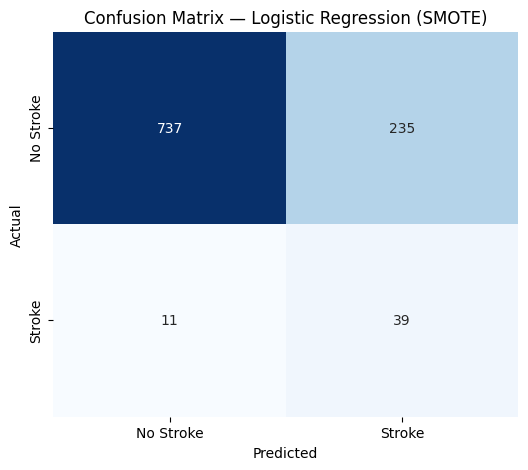

TN, FP, FN, TP: [737 235  11  39]


In [27]:
# CELL 22 — Confusion Matrix: Logistic Regression (SMOTE)
cm_logistic_regression=confusion_matrix(y_test,pred_smote_logistic_regression)
plt.figure(figsize=(6,5))
sns.heatmap(cm_logistic_regression,annot=True,fmt="d",cmap="Blues",cbar=False,
 xticklabels=["No Stroke","Stroke"],yticklabels=["No Stroke","Stroke"])
plt.title("Confusion Matrix — Logistic Regression (SMOTE)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("TN, FP, FN, TP:",cm_logistic_regression.ravel())

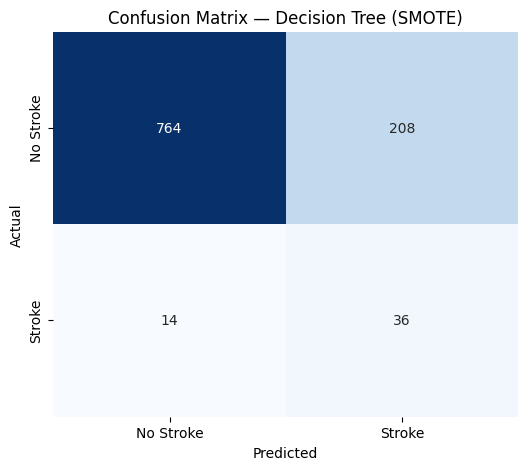

TN, FP, FN, TP: [764 208  14  36]


In [28]:
# CELL 23 — Confusion Matrix: Decision Tree (SMOTE)
cm_decision_tree=confusion_matrix(y_test,pred_smote_decision_tree)
plt.figure(figsize=(6,5))
sns.heatmap(cm_decision_tree,annot=True,fmt="d",cmap="Blues",cbar=False,
 xticklabels=["No Stroke","Stroke"],yticklabels=["No Stroke","Stroke"])
plt.title("Confusion Matrix — Decision Tree (SMOTE)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("TN, FP, FN, TP:",cm_decision_tree.ravel())

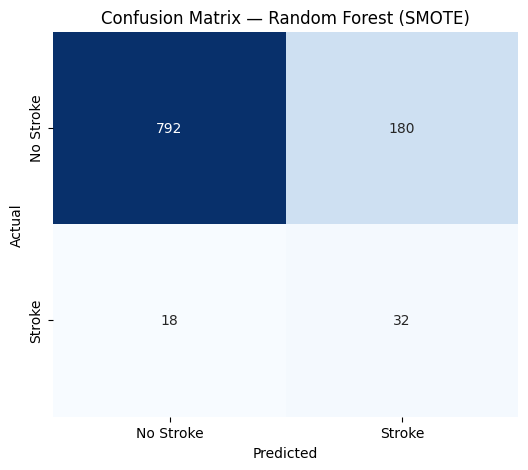

TN, FP, FN, TP: [792 180  18  32]


In [29]:
# CELL 24 — Confusion Matrix: Random Forest (SMOTE)
cm_random_forest=confusion_matrix(y_test,pred_smote_random_forest)
plt.figure(figsize=(6,5))
sns.heatmap(cm_random_forest,annot=True,fmt="d",cmap="Blues",cbar=False,
 xticklabels=["No Stroke","Stroke"],yticklabels=["No Stroke","Stroke"])
plt.title("Confusion Matrix — Random Forest (SMOTE)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("TN, FP, FN, TP:",cm_random_forest.ravel())

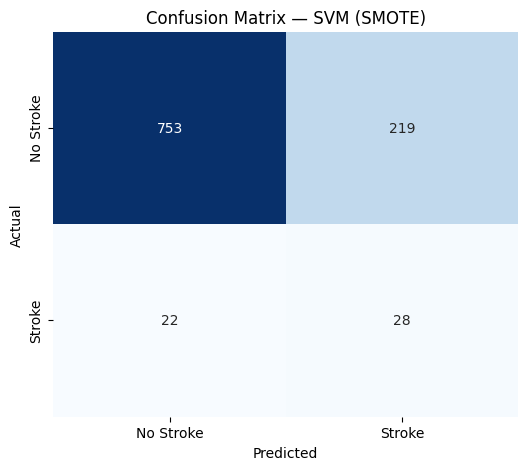

TN, FP, FN, TP: [753 219  22  28]


In [30]:
# CELL 25 — Confusion Matrix: SVM (SMOTE)
cm_svm=confusion_matrix(y_test,pred_smote_svm)
plt.figure(figsize=(6,5))
sns.heatmap(cm_svm,annot=True,fmt="d",cmap="Blues",cbar=False,
 xticklabels=["No Stroke","Stroke"],yticklabels=["No Stroke","Stroke"])
plt.title("Confusion Matrix — SVM (SMOTE)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("TN, FP, FN, TP:",cm_svm.ravel())

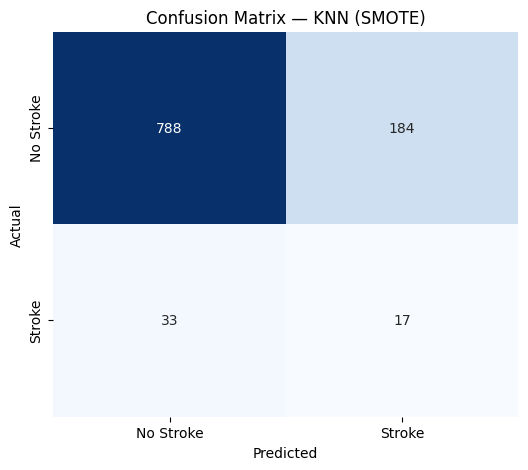

TN, FP, FN, TP: [788 184  33  17]


In [31]:
# CELL 26 — Confusion Matrix: KNN (SMOTE)
cm_knn=confusion_matrix(y_test,pred_smote_knn)
plt.figure(figsize=(6,5))
sns.heatmap(cm_knn,annot=True,fmt="d",cmap="Blues",cbar=False,
 xticklabels=["No Stroke","Stroke"],yticklabels=["No Stroke","Stroke"])
plt.title("Confusion Matrix — KNN (SMOTE)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("TN, FP, FN, TP:",cm_knn.ravel())

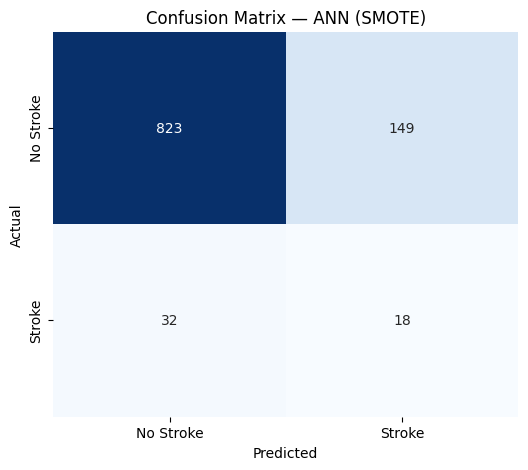

TN, FP, FN, TP: [823 149  32  18]


In [32]:
# CELL 27 — Confusion Matrix: ANN (SMOTE)
cm_ann=confusion_matrix(y_test,pred_smote_ann)
plt.figure(figsize=(6,5))
sns.heatmap(cm_ann,annot=True,fmt="d",cmap="Blues",cbar=False,
 xticklabels=["No Stroke","Stroke"],yticklabels=["No Stroke","Stroke"])
plt.title("Confusion Matrix — ANN (SMOTE)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("TN, FP, FN, TP:",cm_ann.ravel())

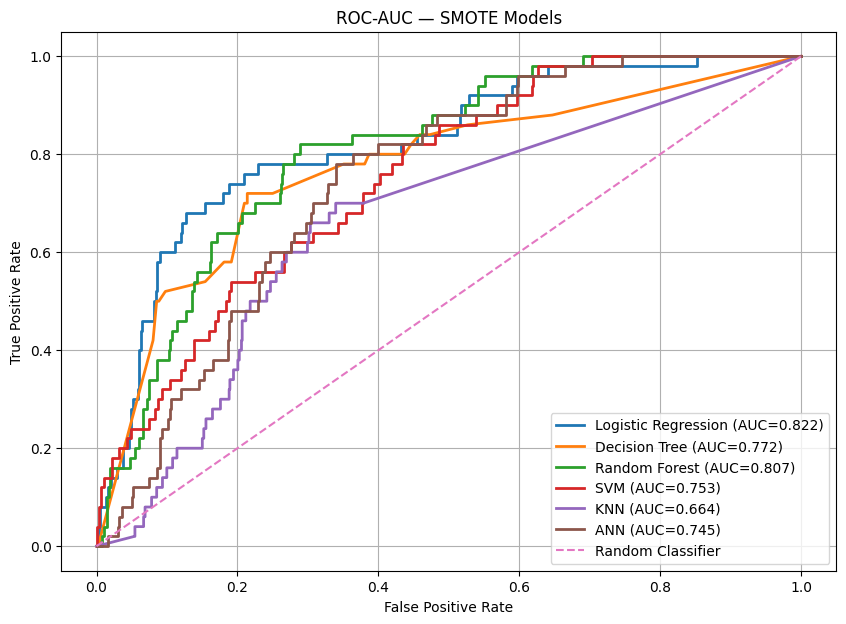

In [33]:
# CELL 28 — ROC-AUC curves for all SMOTE-trained models
smote_roc=[
 ("Logistic Regression",prob_smote_logistic_regression),
 ("Decision Tree",prob_smote_decision_tree),
 ("Random Forest",prob_smote_random_forest),
 ("SVM",prob_smote_svm),("KNN",prob_smote_knn),("ANN",prob_smote_ann)]
plt.figure(figsize=(10,7))
for name,prob in smote_roc:
 fpr,tpr,_=roc_curve(y_test,prob); aucv=roc_auc_score(y_test,prob)
 plt.plot(fpr,tpr,label=f"{name} (AUC={aucv:.3f})",linewidth=2)
plt.plot([0,1],[0,1],"--",label="Random Classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC-AUC — SMOTE Models"); plt.legend(); plt.grid(True); plt.show()

In [34]:
# CELL 29 — Top 3 SMOTE models (F1 first, AUC tie-breaker)
smote_results_df=pd.DataFrame(smote_metrics).sort_values(
 by=["F1-Score","AUC"],ascending=False).reset_index(drop=True)
top_3_smote=smote_results_df.head(3)
display(top_3_smote.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Decision Tree,0.7828,0.1475,0.72,0.2449,0.7725
1,Random Forest,0.8063,0.1509,0.64,0.2443,0.8069
2,Logistic Regression,0.7593,0.1423,0.78,0.2407,0.8219


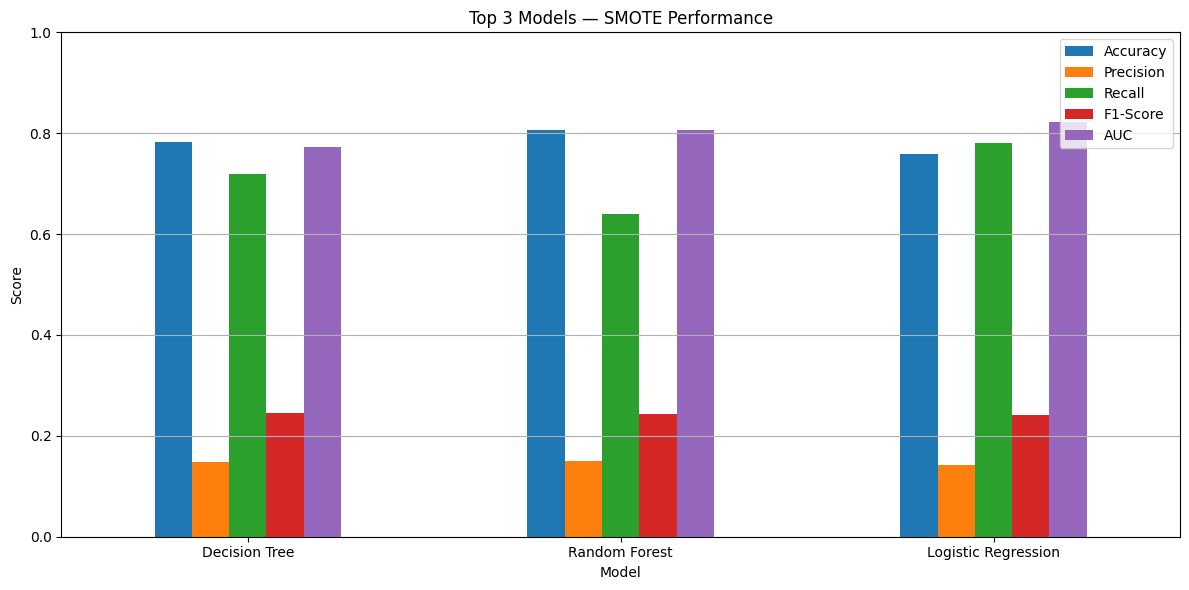

In [35]:
# CELL 30 — Top 3 performance bar chart
top3_chart=top_3_smote.set_index("Model")[["Accuracy","Precision","Recall","F1-Score","AUC"]]
ax=top3_chart.plot(kind="bar",figsize=(12,6))
ax.set_title("Top 3 Models — SMOTE Performance")
ax.set_xlabel("Model"); ax.set_ylabel("Score"); ax.set_ylim(0,1)
plt.xticks(rotation=0); plt.grid(axis="y"); plt.tight_layout(); plt.show()

In [36]:
# CELL 31 — Final Top 3: Original vs SMOTE table
top3_names=top_3_smote["Model"].tolist()
display(comparison_df.loc[top3_names].round(4))

,Accuracy (Original),Precision (Original),Recall (Original),F1-Score (Original),AUC (Original),Accuracy (SMOTE),Precision (SMOTE),Recall (SMOTE),F1-Score (SMOTE),AUC (SMOTE)
Model,,,,,,,,,,
Decision Tree,0.9462,0.0,0.0,0.0,0.7917,0.7828,0.1475,0.72,0.2449,0.7725
Random Forest,0.9511,0.0,0.0,0.0,0.8320,0.8063,0.1509,0.64,0.2443,0.8069
Logistic Regression,0.9511,0.0,0.0,0.0,0.8377,0.7593,0.1423,0.78,0.2407,0.8219


## Notes for interpretation
- SMOTE is applied **only to the training split**; never SMOTE the test data.
- Both original-trained and SMOTE-trained classifiers are evaluated on the same untouched original test set.
- Therefore confusion matrices show the real test class distribution, not a balanced test set.
- Rank Top 3 by F1-Score, with AUC as a tie-breaker. Inspect Recall too because missed stroke cases matter.